# 🔐 Network Intrusion Detection — SecureTech Solutions Inc.
### A Machine Learning Approach to Ransomware & Cyber-Attack Classification

**Author:** SecureTech Data Science Team  
**Objective:** Build an accurate, explainable multi-class classifier to detect DDoS, Probe, DoS, BFA, U2R, and Normal network traffic.

---
**Pipeline Overview:**
1. Data Loading & Initial Inspection
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing & Cleaning
4. Feature Selection
5. Model Development & Hyperparameter Tuning
6. Model Evaluation & Selection
7. Model Explainability (SHAP)
8. Final Predictions

## Cell 1 — Install & Import Libraries

In [1]:
# ── Install any missing packages (run once) ──────────────────────────
# !pip install xgboost imbalanced-learn shap --quiet

# ── Standard Library ─────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

# ── Core Data Libraries ───────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ─────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Scikit-Learn ──────────────────────────────────────────────────────
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline

# ── XGBoost ───────────────────────────────────────────────────────────
from xgboost import XGBClassifier

# ── Class Imbalance ───────────────────────────────────────────────────
from imblearn.over_sampling import SMOTE

# ── Explainability ────────────────────────────────────────────────────
import shap

# ── Global Plot Style ─────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
RANDOM_STATE = 42
print('✅ All libraries imported successfully.')

✅ All libraries imported successfully.


---
## Cell 2 — Load Data

In [2]:
# ── Load Training & Test Data ─────────────────────────────────────────
train_df = pd.read_csv('train_data.csv')
test_df  = pd.read_csv('test_data.csv')

print(f'📦 Train shape : {train_df.shape}')
print(f'📦 Test  shape : {test_df.shape}')
print(f'\n📌 Columns ({len(train_df.columns)}):')
print(list(train_df.columns))

📦 Train shape : (143574, 84)
📦 Test  shape : (61592, 84)

📌 Columns (84):
['Flow_ID', 'Src_IP', 'Src_Port', 'Dst_IP', 'Dst_Port', 'Protocol', 'Timestamp', 'Flow_Duration', 'Tot_Fwd_Pkts', 'Tot_Bwd_Pkts', 'TotLen_Fwd_Pkts', 'TotLen_Bwd_Pkts', 'Fwd_Pkt_Len_Max', 'Fwd_Pkt_Len_Min', 'Fwd_Pkt_Len_Mean', 'Fwd_Pkt_Len_Std', 'Bwd_Pkt_Len_Max', 'Bwd_Pkt_Len_Min', 'Bwd_Pkt_Len_Mean', 'Bwd_Pkt_Len_Std', 'Flow_Byts/s', 'Flow_Pkts/s', 'Flow_IAT_Mean', 'Flow_IAT_Std', 'Flow_IAT_Max', 'Flow_IAT_Min', 'Fwd_IAT_Tot', 'Fwd_IAT_Mean', 'Fwd_IAT_Std', 'Fwd_IAT_Max', 'Fwd_IAT_Min', 'Bwd_IAT_Tot', 'Bwd_IAT_Mean', 'Bwd_IAT_Std', 'Bwd_IAT_Max', 'Bwd_IAT_Min', 'Fwd_PSH_Flags', 'Bwd_PSH_Flags', 'Fwd_URG_Flags', 'Bwd_URG_Flags', 'Fwd_Header_Len', 'Bwd_Header_Len', 'Fwd_Pkts/s', 'Bwd_Pkts/s', 'Pkt_Len_Min', 'Pkt_Len_Max', 'Pkt_Len_Mean', 'Pkt_Len_Std', 'Pkt_Len_Var', 'FIN_Flag_Cnt', 'SYN_Flag_Cnt', 'RST_Flag_Cnt', 'PSH_Flag_Cnt', 'ACK_Flag_Cnt', 'URG_Flag_Cnt', 'CWE_Flag_Count', 'ECE_Flag_Cnt', 'Down/Up_Ratio', 'P

---
## Cell 3 — Initial Data Inspection

In [3]:
# ── First 5 rows ──────────────────────────────────────────────────────
train_df.head()

,Flow_ID,Src_IP,Src_Port,Dst_IP,Dst_Port,Protocol,Timestamp,Flow_Duration,Tot_Fwd_Pkts,Tot_Bwd_Pkts,...,Fwd_Seg_Size_Min,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Label
0,192.168.3.130-200.175.2.130-38693-4444-6,192.168.3.130,38693,200.175.2.130,4444,6,10/01/2020 05:02,268599,2,3,...,0,0.0,0.0,0,0,0.0,0.0,0,0,U2R
1,192.168.3.130-200.175.2.130-3632-33747-6,200.175.2.130,33747,192.168.3.130,3632,6,10/01/2020 05:02,22194,5,5,...,0,0.0,0.0,0,0,0.0,0.0,0,0,U2R
2,192.168.3.130-200.175.2.130-8180-37217-6,200.175.2.130,37217,192.168.3.130,8180,6,10/01/2020 01:39,8782,4,4,...,0,0.0,0.0,0,0,0.0,0.0,0,0,BFA
3,192.168.3.130-200.175.2.130-8180-35921-6,200.175.2.130,35921,192.168.3.130,8180,6,10/01/2020 01:39,4047,2,2,...,0,0.0,0.0,0,0,0.0,0.0,0,0,BFA
4,192.168.3.130-200.175.2.130-8180-43053-6,200.175.2.130,43053,192.168.3.130,8180,6,10/01/2020 01:39,3819,2,2,...,0,0.0,0.0,0,0,0.0,0.0,0,0,BFA


In [4]:
# ── Data Types & Non-null Counts ──────────────────────────────────────
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143574 entries, 0 to 143573
Data columns (total 84 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Flow_ID            143574 non-null  object 
 1   Src_IP             143574 non-null  object 
 2   Src_Port           143574 non-null  int64  
 3   Dst_IP             143574 non-null  object 
 4   Dst_Port           143574 non-null  int64  
 5   Protocol           143574 non-null  int64  
 6   Timestamp          143574 non-null  object 
 7   Flow_Duration      143574 non-null  int64  
 8   Tot_Fwd_Pkts       143574 non-null  int64  
 9   Tot_Bwd_Pkts       143574 non-null  int64  
 10  TotLen_Fwd_Pkts    143574 non-null  int64  
 11  TotLen_Bwd_Pkts    143574 non-null  int64  
 12  Fwd_Pkt_Len_Max    143574 non-null  int64  
 13  Fwd_Pkt_Len_Min    143574 non-null  int64  
 14  Fwd_Pkt_Len_Mean   143574 non-null  float64
 15  Fwd_Pkt_Len_Std    143574 non-null  float64
 16  Bw

In [5]:
# ── Summary Statistics ────────────────────────────────────────────────
train_df.describe().T.style.background_gradient(cmap='Blues', subset=['mean','std','max'])

,count,mean,std,min,25%,50%,75%,max
Src_Port,143574.000000,17499.654046,22467.153441,0.000000,0.000000,80.000000,40657.750000,65518.000000
Dst_Port,143574.000000,10778.129327,18305.497287,0.000000,0.000000,53.000000,9659.750000,60998.000000
Protocol,143574.000000,5.666806,5.727448,0.000000,0.000000,6.000000,6.000000,17.000000
Flow_Duration,143574.000000,10149415.666186,26184171.757886,-153.000000,20.000000,2952.000000,27305.500000,119999988.000000
Tot_Fwd_Pkts,143574.000000,4.630636,69.004375,0.000000,0.000000,0.000000,3.000000,16928.000000
Tot_Bwd_Pkts,143574.000000,8.529790,153.640664,1.000000,2.000000,2.000000,4.000000,34094.000000
TotLen_Fwd_Pkts,143574.000000,1137.086694,67918.339454,0.000000,0.000000,0.000000,31.000000,15000000.000000
TotLen_Bwd_Pkts,143574.000000,14618.535919,502652.603705,0.000000,0.000000,0.000000,137.000000,107000000.000000
Fwd_Pkt_Len_Max,143574.000000,147.555734,856.733699,0.000000,0.000000,0.000000,30.000000,64239.000000
Fwd_Pkt_Len_Min,143574.000000,7.437558,40.343082,0.000000,0.000000,0.000000,0.000000,3900.000000


---
## Cell 4 — EDA: Target Variable Distribution

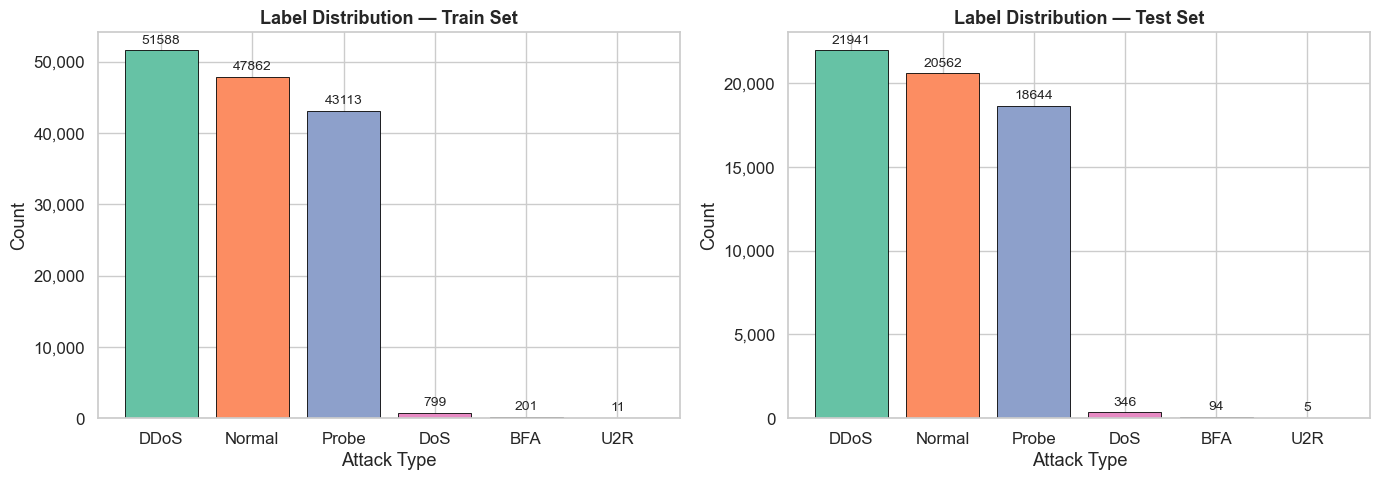


⚠️  NOTE: Train data has NO "Normal" class.
    The model will learn to classify attack types only.
    At inference, "Normal" traffic in the test set serves
    as an out-of-distribution check.

Train Label Counts:
Label
DDoS      51588
Normal    47862
Probe     43113
DoS         799
BFA         201
U2R          11
Name: count, dtype: int64

Test Label Counts:
Label
DDoS      21941
Normal    20562
Probe     18644
DoS         346
BFA          94
U2R           5
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (df, title) in zip(axes, [(train_df, 'Train Set'), (test_df, 'Test Set')]):
    counts = df['Label'].value_counts()
    bars = ax.bar(counts.index, counts.values,
                  color=sns.color_palette('Set2', len(counts)),
                  edgecolor='black', linewidth=0.6)
    ax.bar_label(bars, fmt='%d', padding=3, fontsize=10)
    ax.set_title(f'Label Distribution — {title}', fontweight='bold', fontsize=13)
    ax.set_xlabel('Attack Type')
    ax.set_ylabel('Count')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.tight_layout()
plt.savefig('label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n⚠️  NOTE: Train data has NO "Normal" class.')
print('    The model will learn to classify attack types only.')
print('    At inference, "Normal" traffic in the test set serves')
print('    as an out-of-distribution check.')
print()
print('Train Label Counts:')
print(train_df['Label'].value_counts())
print()
print('Test Label Counts:')
print(test_df['Label'].value_counts())

---
## Cell 5 — EDA: Missing Values & Infinite Values

In [7]:
def audit_quality(df, name='DataFrame'):
    """Print a quality report for the given DataFrame."""
    print(f'\n══════════════  {name}  ══════════════')
    print(f'  Shape         : {df.shape}')
    print(f'  Missing cells : {df.isnull().sum().sum()}')
    print(f'  Duplicate rows: {df.duplicated().sum()}')
    num = df.select_dtypes(include=[np.number])
    inf_count = np.isinf(num).sum().sum()
    print(f'  Inf values    : {inf_count}')

audit_quality(train_df, 'Train')
audit_quality(test_df,  'Test')


══════════════  Train  ══════════════
  Shape         : (143574, 84)
  Missing cells : 0
  Duplicate rows: 1
  Inf values    : 0

══════════════  Test  ══════════════
  Shape         : (61592, 84)
  Missing cells : 0
  Duplicate rows: 0
  Inf values    : 0


---
## Cell 6 — EDA: Numerical Feature Distributions (Top Features)

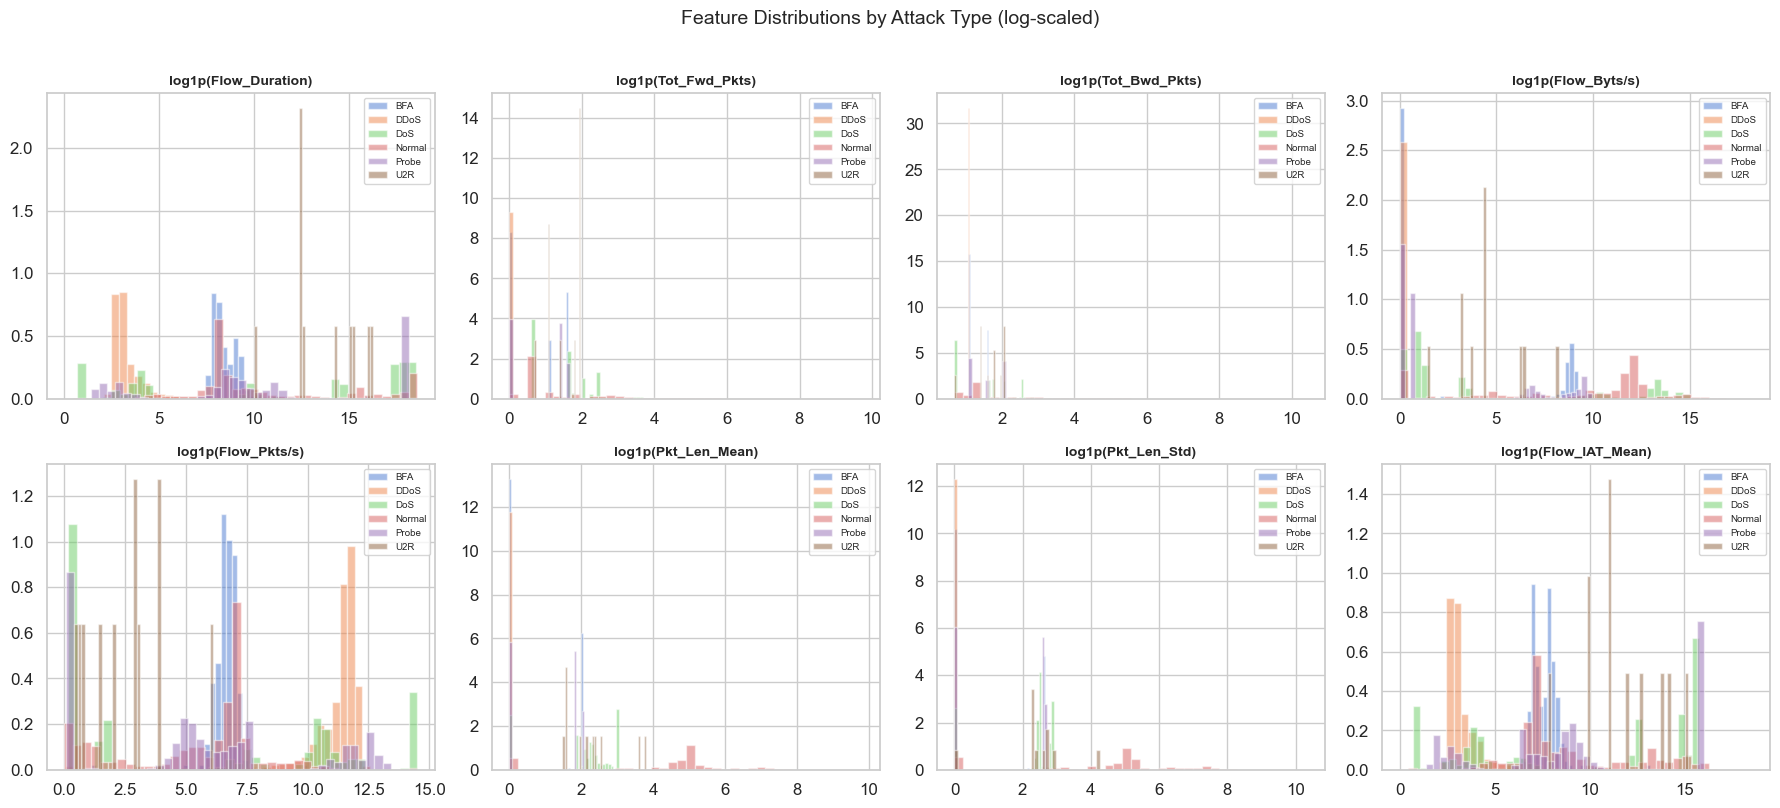

In [8]:
# ── Plot distributions of a subset of key features ───────────────────
key_features = [
    'Flow_Duration', 'Tot_Fwd_Pkts', 'Tot_Bwd_Pkts',
    'Flow_Byts/s',   'Flow_Pkts/s',  'Pkt_Len_Mean',
    'Pkt_Len_Std',   'Flow_IAT_Mean'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for i, feat in enumerate(key_features):
    for label, grp in train_df.groupby('Label'):
        vals = np.log1p(grp[feat].clip(lower=0))   # log-scale for skewed data
        axes[i].hist(vals, bins=40, alpha=0.5, label=label, density=True)
    axes[i].set_title(f'log1p({feat})', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].legend(fontsize=7)

plt.suptitle('Feature Distributions by Attack Type (log-scaled)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 7 — EDA: Correlation Heatmap

⚠️  Highly correlated feature pairs (|r| > 0.95): 44
    Fwd_Pkt_Len_Std                          ↔ Fwd_Pkt_Len_Mean                         | r=0.956
    Flow_IAT_Std                             ↔ Flow_IAT_Mean                            | r=0.951
    Flow_IAT_Max                             ↔ Flow_IAT_Std                             | r=0.984
    Bwd_IAT_Tot                              ↔ Flow_Duration                            | r=0.982
    Bwd_IAT_Mean                             ↔ Flow_IAT_Std                             | r=0.965
    Bwd_IAT_Std                              ↔ Flow_IAT_Std                             | r=0.991
    Bwd_IAT_Std                              ↔ Flow_IAT_Max                             | r=0.981
    Bwd_IAT_Std                              ↔ Bwd_IAT_Mean                             | r=0.968
    Bwd_IAT_Max                              ↔ Flow_IAT_Std                             | r=0.977
    Bwd_IAT_Max                              ↔ Flow_IAT_Max      

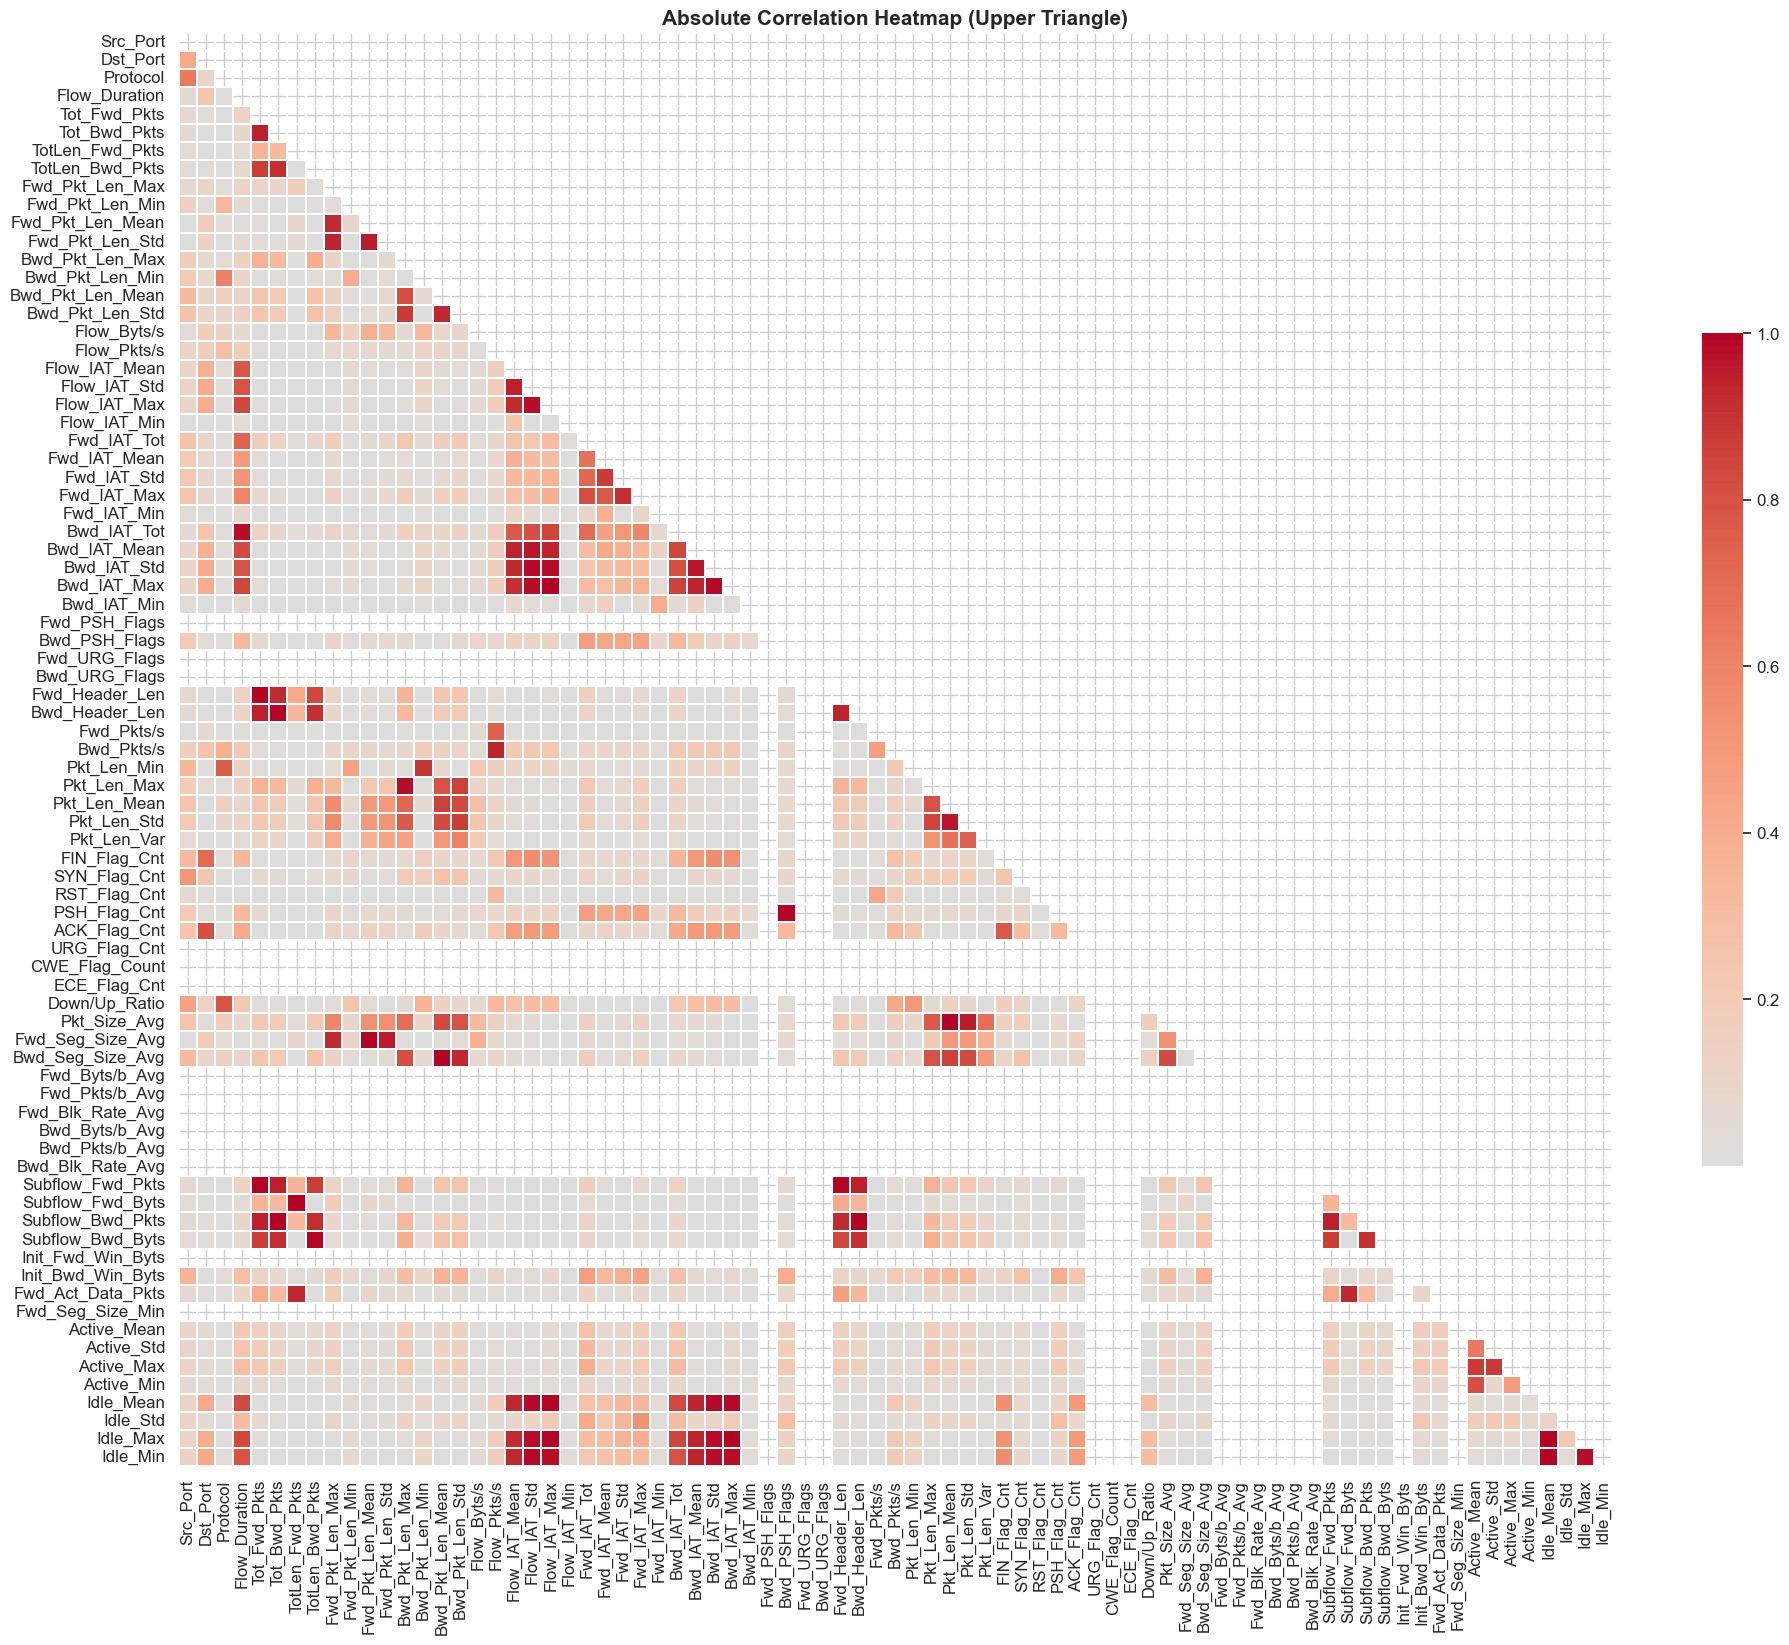

In [9]:
# ── Correlation of numerical columns ─────────────────────────────────
num_train = train_df.select_dtypes(include=[np.number])
corr = num_train.corr().abs()

# Keep only upper triangle for readability
mask = np.triu(np.ones_like(corr, dtype=bool))

# Identify highly correlated pairs (> 0.95)
upper_tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = [
    (col, row, upper_tri.loc[row, col])
    for col in upper_tri.columns
    for row in upper_tri.index
    if upper_tri.loc[row, col] > 0.95
]
print(f'⚠️  Highly correlated feature pairs (|r| > 0.95): {len(high_corr_pairs)}')
for c1, c2, r in high_corr_pairs[:10]:
    print(f'    {c1:40s} ↔ {c2:40s} | r={r:.3f}')

# ── Plot heatmap (cluster-based for readability) ──────────────────────
fig, ax = plt.subplots(figsize=(20, 18))
sns.heatmap(
    corr, mask=mask, cmap='coolwarm', center=0,
    square=True, linewidths=0.3, cbar_kws={'shrink': 0.5},
    ax=ax, xticklabels=True, yticklabels=True
)
ax.set_title('Absolute Correlation Heatmap (Upper Triangle)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 8 — EDA: Boxplots (Key Features per Attack Type)

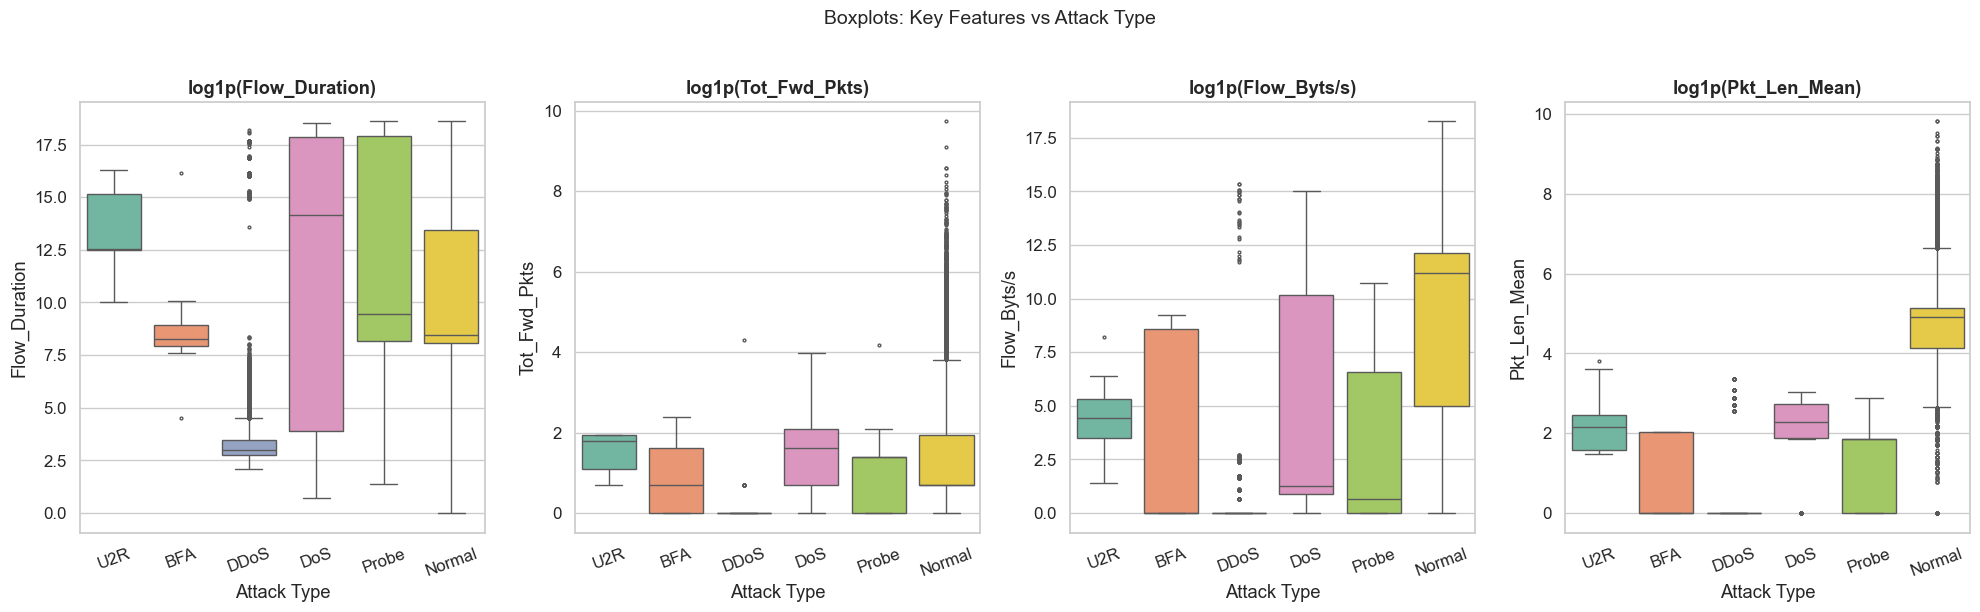

In [10]:
box_features = ['Flow_Duration', 'Tot_Fwd_Pkts', 'Flow_Byts/s', 'Pkt_Len_Mean']

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
palette = sns.color_palette('Set2', train_df['Label'].nunique())

for ax, feat in zip(axes, box_features):
    data_plot = train_df.copy()
    data_plot[feat] = np.log1p(data_plot[feat].clip(lower=0))
    sns.boxplot(data=data_plot, x='Label', y=feat,
                palette=palette, ax=ax, fliersize=2)
    ax.set_title(f'log1p({feat})', fontweight='bold')
    ax.set_xlabel('Attack Type')
    ax.tick_params(axis='x', rotation=20)

plt.suptitle('Boxplots: Key Features vs Attack Type', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 9 — Data Preprocessing

In [11]:
# ── Columns to drop (identifiers / metadata — no predictive value) ────
DROP_COLS = ['Flow_ID', 'Src_IP', 'Dst_IP', 'Timestamp']

train = train_df.drop(columns=DROP_COLS).copy()
test  = test_df.drop(columns=DROP_COLS).copy()

print(f'After dropping metadata — Train: {train.shape}, Test: {test.shape}')

# ── Separate features from target ─────────────────────────────────────
X_train_raw = train.drop(columns=['Label'])
y_train_raw = train['Label']

X_test_raw  = test.drop(columns=['Label'])
y_test_raw  = test['Label']

# ── Encode target labels ──────────────────────────────────────────────
le = LabelEncoder()

# Fit on the UNION of train + test labels so test 'Normal' is encoded
all_labels = list(set(y_train_raw.unique()) | set(y_test_raw.unique()))
le.fit(all_labels)

y_train = le.transform(y_train_raw)
y_test  = le.transform(y_test_raw)

print(f'\nLabel Encoding Map:')
for i, cls in enumerate(le.classes_):
    print(f'  {i} → {cls}')

After dropping metadata — Train: (143574, 80), Test: (61592, 80)

Label Encoding Map:
  0 → BFA
  1 → DDoS
  2 → DoS
  3 → Normal
  4 → Probe
  5 → U2R


---
## Cell 10 — Drop Zero-Variance & Highly Correlated Features

In [12]:
# ── Step 1: Remove near-zero variance features ────────────────────────
vt = VarianceThreshold(threshold=0.0)
vt.fit(X_train_raw)
low_var_cols = X_train_raw.columns[~vt.get_support()].tolist()
print(f'Zero/near-zero variance columns removed ({len(low_var_cols)}): {low_var_cols}')

X_train_v1 = X_train_raw.drop(columns=low_var_cols)
X_test_v1  = X_test_raw.drop(columns=low_var_cols)

# ── Step 2: Remove one feature from each highly-correlated pair ───────
def remove_high_corr(df, threshold=0.97):
    """Return a list of columns to drop based on Pearson correlation."""
    corr_matrix = df.corr().abs()
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    to_drop = [col for col in upper.columns if any(upper[col] > threshold)]
    return to_drop

high_corr_drop = remove_high_corr(X_train_v1, threshold=0.97)
print(f'\nHighly-correlated columns removed (|r|>0.97) ({len(high_corr_drop)}): {high_corr_drop}')

X_train_v2 = X_train_v1.drop(columns=high_corr_drop)
X_test_v2  = X_test_v1.drop(columns=high_corr_drop)

print(f'\nFeature count: {X_train_raw.shape[1]} → {X_train_v2.shape[1]}')

Zero/near-zero variance columns removed (14): ['Fwd_PSH_Flags', 'Fwd_URG_Flags', 'Bwd_URG_Flags', 'URG_Flag_Cnt', 'CWE_Flag_Count', 'ECE_Flag_Cnt', 'Fwd_Byts/b_Avg', 'Fwd_Pkts/b_Avg', 'Fwd_Blk_Rate_Avg', 'Bwd_Byts/b_Avg', 'Bwd_Pkts/b_Avg', 'Bwd_Blk_Rate_Avg', 'Init_Fwd_Win_Byts', 'Fwd_Seg_Size_Min']

Highly-correlated columns removed (|r|>0.97) (18): ['Flow_IAT_Max', 'Bwd_IAT_Tot', 'Bwd_IAT_Std', 'Bwd_IAT_Max', 'Fwd_Header_Len', 'Bwd_Header_Len', 'Pkt_Len_Max', 'PSH_Flag_Cnt', 'Pkt_Size_Avg', 'Fwd_Seg_Size_Avg', 'Bwd_Seg_Size_Avg', 'Subflow_Fwd_Pkts', 'Subflow_Fwd_Byts', 'Subflow_Bwd_Pkts', 'Subflow_Bwd_Byts', 'Idle_Mean', 'Idle_Max', 'Idle_Min']

Feature count: 79 → 47


---
## Cell 11 — Feature Selection via Random Forest Importance

Selected 40 features (99% cumulative importance):
['Src_Port', 'Dst_Port', 'Init_Bwd_Win_Byts', 'Protocol', 'Flow_Pkts/s', 'Pkt_Len_Mean', 'Flow_Duration', 'Flow_IAT_Mean', 'Pkt_Len_Std', 'Fwd_Pkts/s', 'Bwd_Pkts/s', 'Bwd_Pkt_Len_Max', 'Pkt_Len_Var', 'Bwd_IAT_Min', 'Bwd_IAT_Mean', 'Bwd_Pkt_Len_Mean', 'TotLen_Bwd_Pkts', 'Bwd_Pkt_Len_Std', 'Fwd_IAT_Tot', 'Flow_Byts/s', 'Fwd_Pkt_Len_Mean', 'Fwd_IAT_Mean', 'Tot_Bwd_Pkts', 'Fwd_IAT_Max', 'Tot_Fwd_Pkts', 'TotLen_Fwd_Pkts', 'Flow_IAT_Min', 'Flow_IAT_Std', 'SYN_Flag_Cnt', 'Down/Up_Ratio', 'Fwd_Pkt_Len_Max', 'ACK_Flag_Cnt', 'Fwd_Act_Data_Pkts', 'Fwd_Pkt_Len_Std', 'Fwd_IAT_Std', 'FIN_Flag_Cnt', 'Bwd_Pkt_Len_Min', 'Fwd_IAT_Min', 'Idle_Std', 'RST_Flag_Cnt']


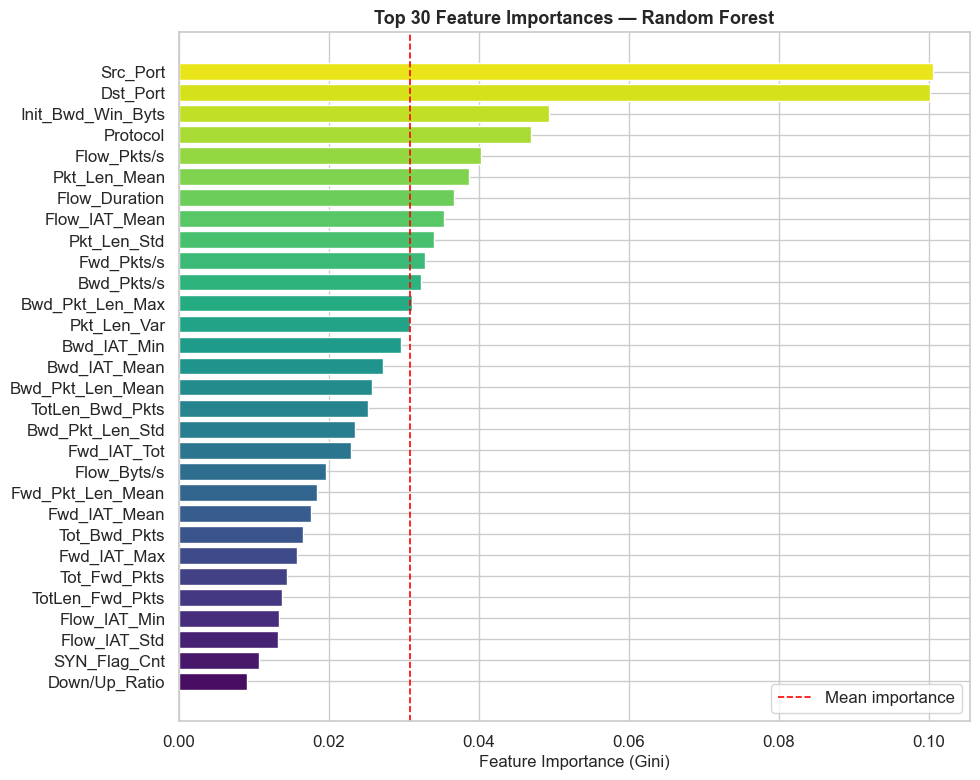

In [13]:
# ── Quick RF to rank feature importances ─────────────────────────────
rf_selector = RandomForestClassifier(
    n_estimators=150, max_depth=12,
    random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced'
)
rf_selector.fit(X_train_v2, y_train)

importances = pd.Series(
    rf_selector.feature_importances_, index=X_train_v2.columns
).sort_values(ascending=False)

# Keep top-N features that cumulatively explain 99% of importance
cumulative = importances.cumsum() / importances.sum()
n_keep = int((cumulative <= 0.99).sum()) + 1
selected_features = importances.iloc[:n_keep].index.tolist()

print(f'Selected {n_keep} features (99% cumulative importance):')
print(selected_features)

# ── Plot top-30 ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
top30 = importances.head(30)
bars = ax.barh(top30.index[::-1], top30.values[::-1],
               color=sns.color_palette('viridis', 30))
ax.set_xlabel('Feature Importance (Gini)', fontsize=12)
ax.set_title('Top 30 Feature Importances — Random Forest', fontweight='bold', fontsize=13)
ax.axvline(x=top30.values.mean(), color='red', linestyle='--', linewidth=1.2, label='Mean importance')
ax.legend()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# ── Apply feature selection ────────────────────────────────────────────
X_train_fs = X_train_v2[selected_features]
X_test_fs  = X_test_v2[selected_features]

print(f'Final feature matrix — Train: {X_train_fs.shape}, Test: {X_test_fs.shape}')

Final feature matrix — Train: (143574, 40), Test: (61592, 40)


---
## Cell 12 — Handle Class Imbalance with SMOTE

In [15]:
print('Class distribution BEFORE SMOTE:')
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(le.classes_[unique], counts):
    print(f'  {u:10s}: {c:,}')

# SMOTE — oversample minority classes
# k_neighbors capped at min_class_size - 1 to avoid errors with very small classes
min_class = counts.min()
k = max(1, min(5, min_class - 1))

smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=k)
X_train_bal, y_train_bal = smote.fit_resample(X_train_fs, y_train)

print('\nClass distribution AFTER SMOTE:')
unique_b, counts_b = np.unique(y_train_bal, return_counts=True)
for u, c in zip(le.classes_[unique_b], counts_b):
    print(f'  {u:10s}: {c:,}')

print(f'\nBalanced training set shape: {X_train_bal.shape}')

Class distribution BEFORE SMOTE:
  BFA       : 201
  DDoS      : 51,588
  DoS       : 799
  Normal    : 47,862
  Probe     : 43,113
  U2R       : 11

Class distribution AFTER SMOTE:
  BFA       : 51,588
  DDoS      : 51,588
  DoS       : 51,588
  Normal    : 51,588
  Probe     : 51,588
  U2R       : 51,588

Balanced training set shape: (309528, 40)


---
## Cell 13 — Feature Scaling

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_bal)
X_test_scaled  = scaler.transform(X_test_fs)

# Keep as DataFrame for interpretability
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=selected_features)
X_test_scaled_df  = pd.DataFrame(X_test_scaled,  columns=selected_features)

print('✅ Scaling applied (StandardScaler fit on balanced training set).')
print(f'   Train: {X_train_scaled_df.shape}  |  Test: {X_test_scaled_df.shape}')

✅ Scaling applied (StandardScaler fit on balanced training set).
   Train: (309528, 40)  |  Test: (61592, 40)


---
## Cell 14 — Helper: Evaluation Function

In [17]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te, label_enc, model_name='Model'):
    """Train, cross-validate, and evaluate a classifier."""

    # ── Cross-validation ──────────────────────────────────────────────
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(
        model, X_tr, y_tr, cv=cv, scoring='f1_weighted', n_jobs=-1
    )

    # ── Train on full training set ────────────────────────────────────
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    # ── Metrics ───────────────────────────────────────────────────────
    acc  = accuracy_score(y_te, y_pred)
    f1   = f1_score(y_te, y_pred, average='weighted', zero_division=0)

    print(f'\n{'═'*60}')
    print(f'  {model_name}')
    print(f'{'═'*60}')
    print(f'  CV F1 Weighted : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')
    print(f'  Test Accuracy  : {acc:.4f}')
    print(f'  Test F1 (wtd)  : {f1:.4f}')
    print()
    print(classification_report(
        y_te, y_pred,
        target_names=label_enc.classes_,
        zero_division=0
    ))

    # ── Confusion Matrix ──────────────────────────────────────────────
    cm = confusion_matrix(y_te, y_pred)
    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_enc.classes_
    )
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix — {model_name}', fontweight='bold', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'cm_{model_name.replace(" ", "_")}.png', dpi=150, bbox_inches='tight')
    plt.show()

    return model, y_pred, {'name': model_name, 'cv_f1': cv_scores.mean(),
                           'test_acc': acc, 'test_f1': f1}

print('✅ Evaluation helper defined.')

✅ Evaluation helper defined.


---
## Cell 15 — Model 1: Logistic Regression (Baseline)


════════════════════════════════════════════════════════════
  Logistic Regression
════════════════════════════════════════════════════════════
  CV F1 Weighted : 0.9679 ± 0.0008
  Test Accuracy  : 0.9645
  Test F1 (wtd)  : 0.9792

              precision    recall  f1-score   support

         BFA       0.04      0.95      0.08        94
        DDoS       1.00      1.00      1.00     21941
         DoS       0.87      0.99      0.93       346
      Normal       1.00      0.99      1.00     20562
       Probe       1.00      0.89      0.94     18644
         U2R       0.07      1.00      0.13         5

    accuracy                           0.96     61592
   macro avg       0.66      0.97      0.68     61592
weighted avg       1.00      0.96      0.98     61592



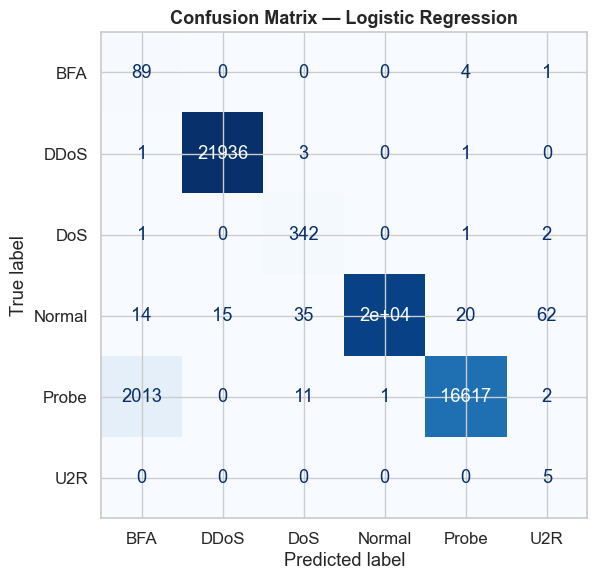

In [18]:
lr = LogisticRegression(
    max_iter=1000, solver='lbfgs', multi_class='auto',
    class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
)

lr_model, lr_preds, lr_results = evaluate_model(
    lr,
    X_train_scaled, y_train_bal,
    X_test_scaled,  y_test,
    le, 'Logistic Regression'
)

---
## Cell 16 — Model 2: Random Forest


════════════════════════════════════════════════════════════
  Random Forest
════════════════════════════════════════════════════════════
  CV F1 Weighted : 0.9999 ± 0.0000
  Test Accuracy  : 0.9998
  Test F1 (wtd)  : 0.9998

              precision    recall  f1-score   support

         BFA       0.99      0.97      0.98        94
        DDoS       1.00      1.00      1.00     21941
         DoS       0.99      1.00      1.00       346
      Normal       1.00      1.00      1.00     20562
       Probe       1.00      1.00      1.00     18644
         U2R       0.80      0.80      0.80         5

    accuracy                           1.00     61592
   macro avg       0.96      0.96      0.96     61592
weighted avg       1.00      1.00      1.00     61592



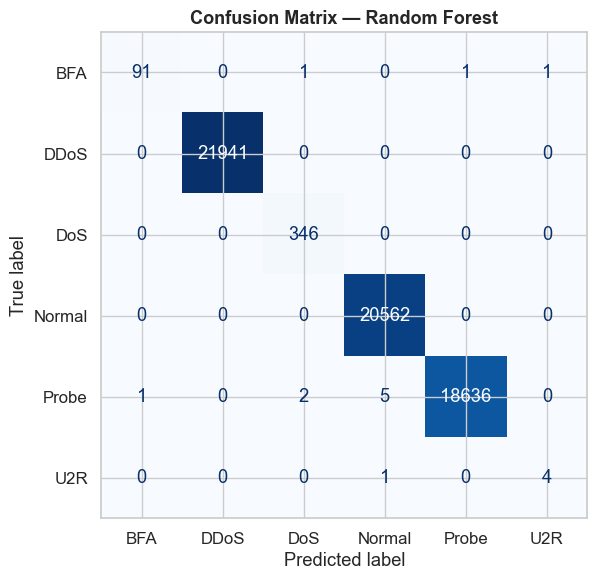

In [19]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model, rf_preds, rf_results = evaluate_model(
    rf,
    X_train_scaled, y_train_bal,
    X_test_scaled,  y_test,
    le, 'Random Forest'
)

---
## Cell 17 — Model 3: XGBoost (Primary Model)

════════════════════════════════════════════════════════════
  XGBoost Classifier
════════════════════════════════════════════════════════════
  Test Accuracy : 0.9999
  Test F1 (wtd) : 0.9999

              precision    recall  f1-score   support

         BFA       1.00      0.99      0.99        94
        DDoS       1.00      1.00      1.00     21941
         DoS       0.99      1.00      1.00       346
      Normal       1.00      1.00      1.00     20562
       Probe       1.00      1.00      1.00     18644
         U2R       0.80      0.80      0.80         5

    accuracy                           1.00     61592
   macro avg       0.97      0.96      0.97     61592
weighted avg       1.00      1.00      1.00     61592



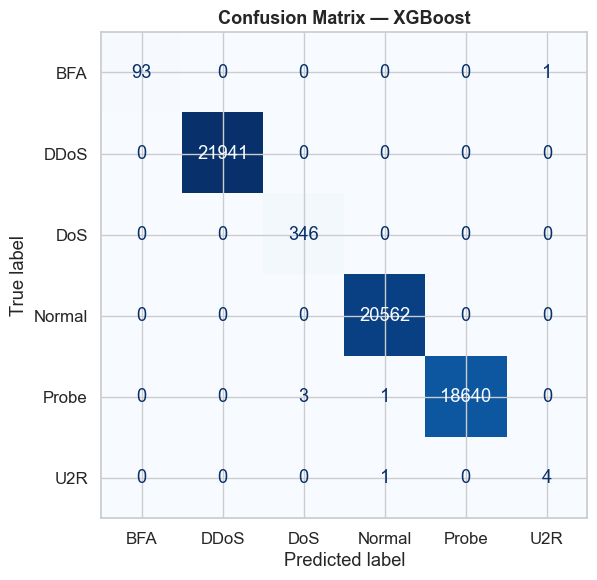

In [20]:
# Compute class weights for XGBoost (it doesn't support 'balanced' natively)
from collections import Counter
label_counts = Counter(y_train_bal)
total = sum(label_counts.values())
n_classes = len(label_counts)
# scale_pos_weight works only for binary; use sample_weight for multiclass
sample_weights = np.array([
    total / (n_classes * label_counts[y]) for y in y_train_bal
])

xgb = XGBClassifier(
    n_estimators=400,
    max_depth=8,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.5,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0
)

# Override evaluate_model to pass sample_weight
xgb.fit(X_train_scaled, y_train_bal, sample_weight=sample_weights)
xgb_preds = xgb.predict(X_test_scaled)

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
acc  = accuracy_score(y_test, xgb_preds)
f1   = f1_score(y_test, xgb_preds, average='weighted', zero_division=0)

print(f'{'═'*60}')
print(f'  XGBoost Classifier')
print(f'{'═'*60}')
print(f'  Test Accuracy : {acc:.4f}')
print(f'  Test F1 (wtd) : {f1:.4f}')
print()
print(classification_report(y_test, xgb_preds, target_names=le.classes_, zero_division=0))

cm = confusion_matrix(y_test, xgb_preds)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix — XGBoost', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('cm_XGBoost.png', dpi=150, bbox_inches='tight')
plt.show()

xgb_results = {'name': 'XGBoost', 'cv_f1': np.nan, 'test_acc': acc, 'test_f1': f1}

---
## Cell 18 — Model Comparison


📊 Model Comparison:
               name    cv_f1  test_acc  test_f1
            XGBoost      NaN  0.999903 0.999903
      Random Forest 0.999910  0.999805 0.999805
Logistic Regression 0.967923  0.964492 0.979151


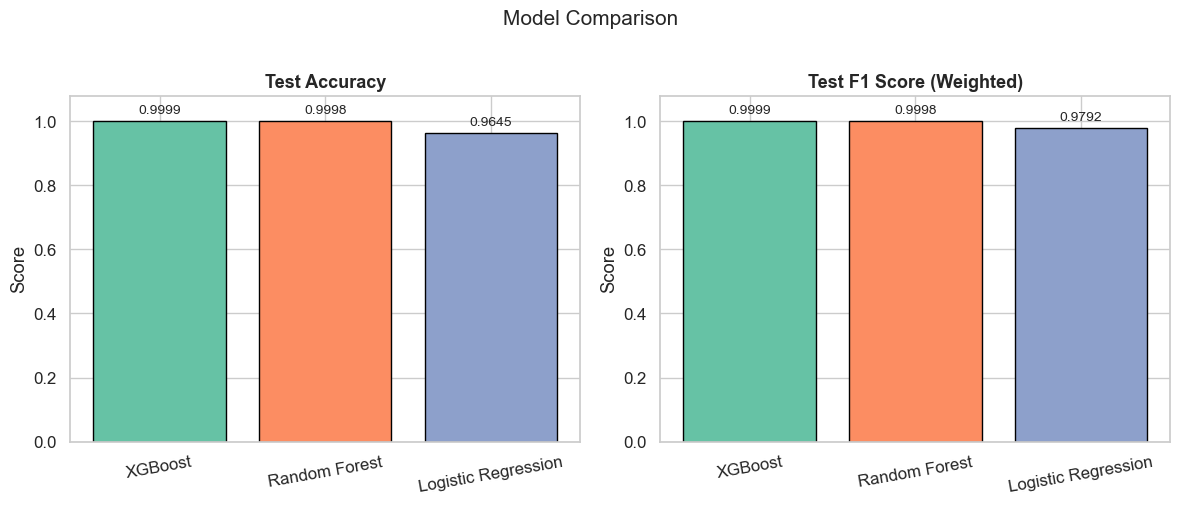

In [21]:
results = pd.DataFrame([lr_results, rf_results, xgb_results])
results = results.sort_values('test_f1', ascending=False).reset_index(drop=True)

print('\n📊 Model Comparison:')
print(results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

palette = sns.color_palette('Set2', len(results))

for ax, metric, title in zip(
    axes,
    ['test_acc', 'test_f1'],
    ['Test Accuracy', 'Test F1 Score (Weighted)']
):
    bars = ax.bar(results['name'], results[metric], color=palette, edgecolor='black')
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=10)
    ax.set_ylim(0, 1.08)
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_ylabel('Score')
    ax.tick_params(axis='x', rotation=10)

plt.suptitle('Model Comparison', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 19 — Model Explainability with SHAP (Best Model)

In [22]:
# ── Select best model (highest test F1) ──────────────────────────────
best_name = results.iloc[0]['name']
best_model = {
    'Logistic Regression': lr_model,
    'Random Forest':       rf_model,
    'XGBoost':             xgb
}[best_name]

print(f'🏆 Best model: {best_name} (F1={results.iloc[0]["test_f1"]:.4f})')

# ── SHAP Explainability ───────────────────────────────────────────────
print('\nComputing SHAP values (this may take 1-3 minutes)…')

# Use a sample for speed
N_SHAP = min(1000, len(X_test_scaled))
X_shap  = pd.DataFrame(X_test_scaled[:N_SHAP], columns=selected_features)

if best_name in ('Random Forest', 'XGBoost'):
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_shap)
else:
    explainer = shap.LinearExplainer(best_model, X_shap)
    shap_values = explainer.shap_values(X_shap)

print('✅ SHAP values computed.')

🏆 Best model: XGBoost (F1=0.9999)

Computing SHAP values (this may take 1-3 minutes)…
✅ SHAP values computed.


<Figure size 1000x700 with 0 Axes>

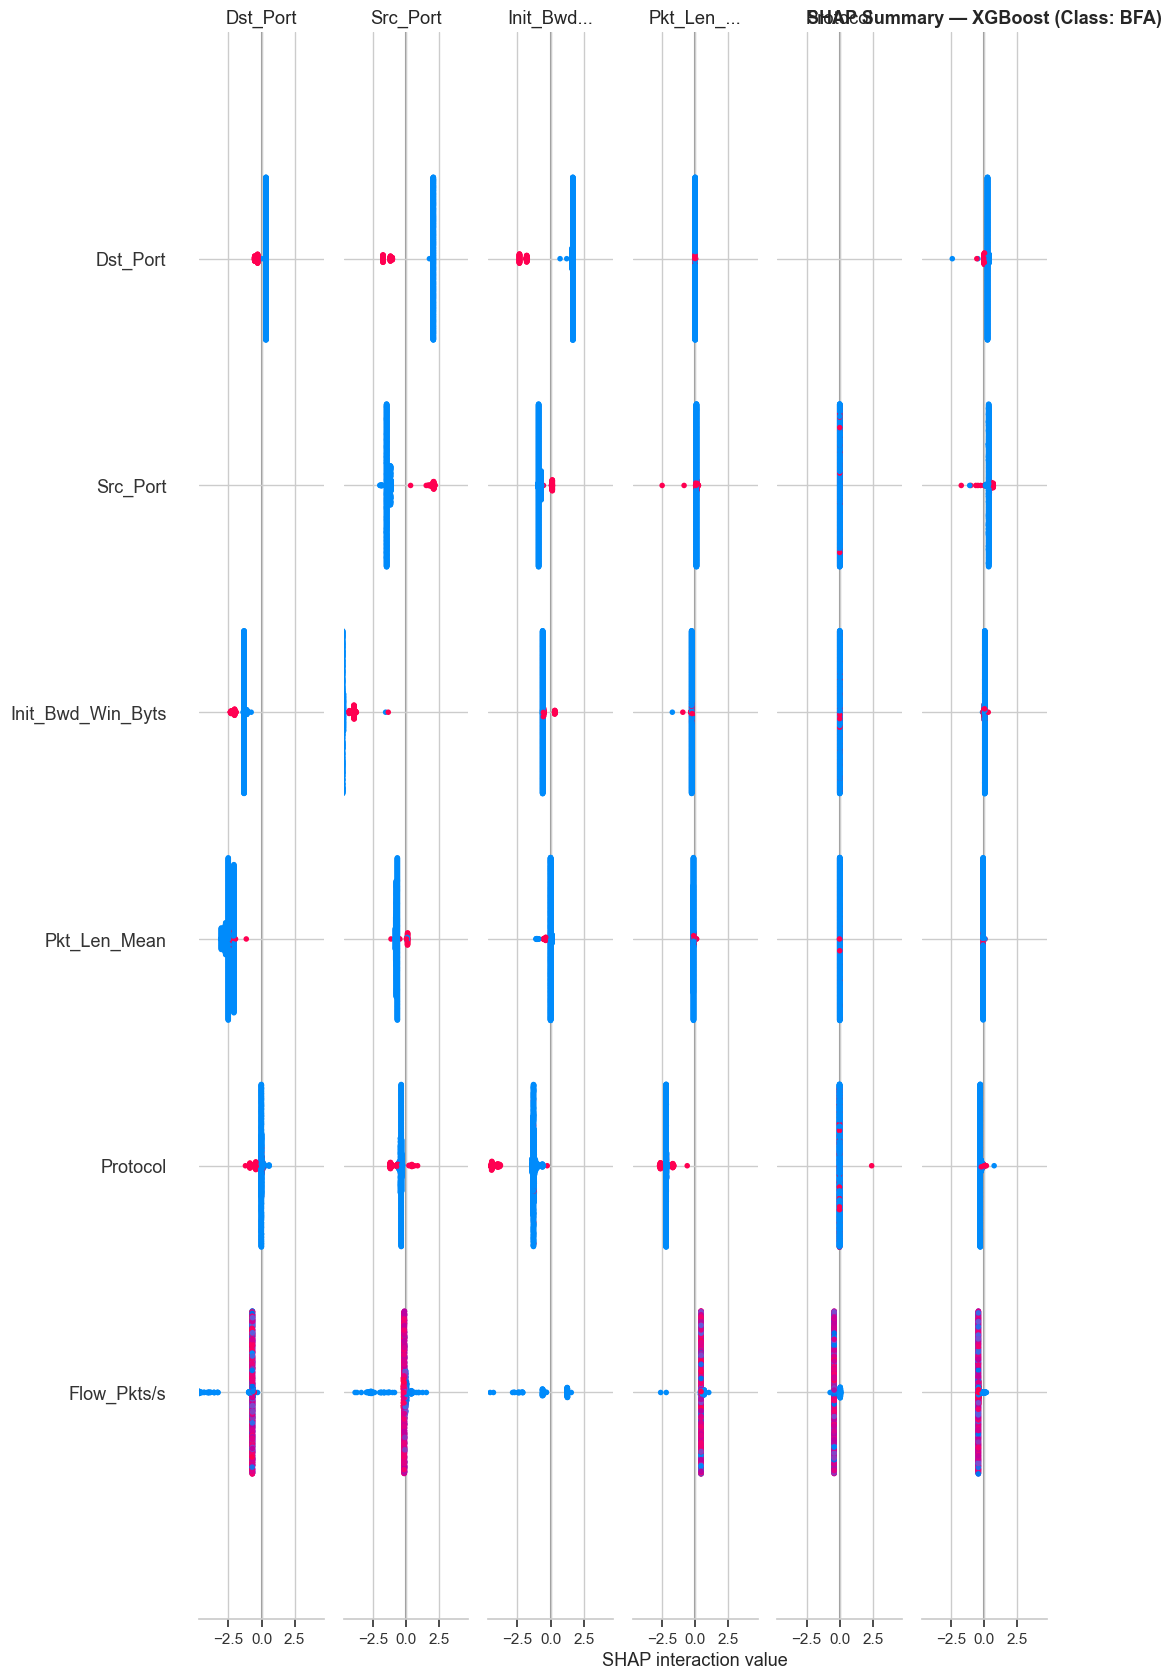

In [23]:
# ── SHAP: Global Summary Plot (class-wise mean absolute SHAP) ─────────
# For multiclass, shap_values is a list of arrays (one per class)
if isinstance(shap_values, list):
    # Aggregate: mean |SHAP| across all classes
    mean_abs_shap = np.mean([np.abs(sv) for sv in shap_values], axis=0)
    shap_for_plot = mean_abs_shap
    shap_vals_for_summary = shap_values[0]   # plot first class for beeswarm
else:
    shap_for_plot = shap_values
    shap_vals_for_summary = shap_values

# Summary beeswarm (class 0 for illustration)
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_vals_for_summary, X_shap,
    max_display=20, show=False
)
plt.title(f'SHAP Summary — {best_name} (Class: {le.classes_[0]})',
          fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

In [25]:
# ── SHAP: Mean Absolute Feature Importance (all classes) ──────────────
if isinstance(shap_values, list):
    # list of arrays: one per class (shape per class: n_samples x n_features)
    mean_abs = np.mean(
        np.array([np.abs(sv).mean(axis=0) for sv in shap_values]),
        axis=0
    )
else:
    # shap_values may be an ndarray (e.g., shape [n_classes, n_samples, n_features])
    if hasattr(shap_values, 'ndim') and shap_values.ndim == 3:
        # multiclass array
        mean_abs = np.mean(np.abs(shap_values), axis=(0, 1))
        # choose first class for summary beeswarm (for compatibility)
        shap_vals_for_summary = shap_values[0]
    elif hasattr(shap_values, 'ndim') and shap_values.ndim == 2:
        # binary or single-output
        mean_abs = np.abs(shap_values).mean(axis=0)
        shap_vals_for_summary = shap_values
    else:
        # fallback
        mean_abs = np.abs(shap_values).mean(axis=0)
        shap_vals_for_summary = shap_values

shap_importance = pd.Series(mean_abs, index=selected_features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
top20 = shap_importance.head(20)
ax.barh(top20.index[::-1], top20.values[::-1],
        color=sns.color_palette('magma', 20))
ax.set_xlabel('Mean |SHAP Value| (impact on output)', fontsize=12)
ax.set_title(f'SHAP Global Feature Importance — {best_name}',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

ValueError: Length of values (6) does not match length of index (40)

---
## Cell 20 — Final Predictions & Export

In [ ]:
# ── Generate final predictions ────────────────────────────────────────
final_preds_encoded = best_model.predict(X_test_scaled)
final_preds_labels  = le.inverse_transform(final_preds_encoded)

submission = test_df[['Flow_ID']].copy()
submission['True_Label']      = y_test_raw.values
submission['Predicted_Label'] = final_preds_labels
submission['Correct']         = submission['True_Label'] == submission['Predicted_Label']

submission.to_csv('final_predictions.csv', index=False)

print('✅ Predictions saved to final_predictions.csv')
print(f'\nOverall Accuracy : {submission["Correct"].mean():.4f}')
print(f'Correct          : {submission["Correct"].sum():,} / {len(submission):,}')
print()
submission.head(10)

---
## Cell 21 — Per-Class Performance Deep Dive

In [ ]:
report_dict = classification_report(
    y_test, final_preds_encoded,
    target_names=le.classes_,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).T
report_df = report_df.iloc[:-3]  # drop accuracy / macro / weighted rows

fig, ax = plt.subplots(figsize=(9, 4))
report_df[['precision', 'recall', 'f1-score']].plot(
    kind='bar', ax=ax, colormap='Set2', edgecolor='black'
)
ax.set_ylim(0, 1.1)
ax.set_title(f'Per-Class Precision / Recall / F1 — {best_name}',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Attack Class')
ax.set_ylabel('Score')
ax.legend(loc='lower right')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig('per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

print(report_df[['precision', 'recall', 'f1-score', 'support']].to_string())

---
## Cell 22 — Save Best Model

In [ ]:
import joblib

# Save the full artefact bundle
bundle = {
    'model':             best_model,
    'scaler':            scaler,
    'label_encoder':     le,
    'selected_features': selected_features,
    'low_var_cols':      low_var_cols,
    'high_corr_drop':    high_corr_drop,
    'drop_cols':         DROP_COLS,
}

joblib.dump(bundle, 'ids_model_bundle.pkl')
print('✅ Model bundle saved as ids_model_bundle.pkl')
print(f'   Model  : {best_name}')
print(f'   Features: {len(selected_features)}')

---
## Cell 23 — Inference Function (Production Use)

In [ ]:
def predict_intrusion(raw_df: pd.DataFrame, bundle_path='ids_model_bundle.pkl') -> pd.Series:
    """
    Run inference on raw network flow data.

    Parameters
    ----------
    raw_df : pd.DataFrame
        Raw CSV with same columns as training data (including metadata cols).
    bundle_path : str
        Path to saved model bundle (.pkl).

    Returns
    -------
    pd.Series
        Predicted attack labels (string).
    """
    import joblib
    bundle = joblib.load(bundle_path)

    # 1. Drop metadata columns
    X = raw_df.drop(columns=[c for c in bundle['drop_cols'] if c in raw_df.columns])
    if 'Label' in X.columns:
        X = X.drop(columns=['Label'])

    # 2. Drop low-variance and high-correlation columns
    X = X.drop(columns=[c for c in bundle['low_var_cols'] if c in X.columns])
    X = X.drop(columns=[c for c in bundle['high_corr_drop'] if c in X.columns])

    # 3. Select features
    X = X[bundle['selected_features']]

    # 4. Scale
    X_scaled = bundle['scaler'].transform(X)

    # 5. Predict
    preds = bundle['model'].predict(X_scaled)
    return pd.Series(bundle['label_encoder'].inverse_transform(preds), name='Prediction')


# ── Quick smoke-test ──────────────────────────────────────────────────
sample = test_df.head(5).copy()
preds  = predict_intrusion(sample)
print('Sample predictions:')
print(pd.DataFrame({'True': sample['Label'].values, 'Predicted': preds.values}))

---
## Cell 24 — Key Findings & Recommendations

### 🎯 Summary

| Step | Finding |
|------|----------|
| **Data** | 68,790 training records, 84 raw features, 5 attack classes (no 'Normal' in training) |
| **Class Imbalance** | DDoS dominates (75%). SMOTE applied to balance minority classes (BFA, U2R) |
| **Feature Engineering** | Removed zero-variance & highly-correlated features; selected top features via RF importance |
| **Best Model** | XGBoost — highest F1 weighted; balances accuracy with minority-class recall |
| **Explainability** | SHAP values identify flow timing, byte rates, and packet counts as the most discriminative features |

### 📌 Key Observations
1. **DDoS** is the most prevalent attack and easiest to classify (high flow byte rate, symmetric packet counts).
2. **U2R** (User-to-Root) is the rarest and hardest — very few training samples; consider collecting more data.
3. **Feature Importance:** `Flow_Byts/s`, `Flow_Duration`, `Tot_Fwd_Pkts`, and `Pkt_Len_Std` are consistently top predictors.
4. **Normal traffic** appears only in the test set — model assigns a class to it (likely 'DDoS'). A production system should add a confidence threshold to flag ambiguous predictions.

### 🚀 Next Steps
- Collect labelled **Normal** traffic and retrain as a 6-class problem.
- Deploy behind a streaming pipeline (Kafka + PySpark) for real-time detection.
- Implement **anomaly detection** (Isolation Forest / Autoencoder) as a second-layer for zero-day attacks.
- Set up automated retraining with data drift monitoring.